In [1]:
# %matplotlib widget

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from helper_functions import filtering, analysis, plotting, diagnostics
from obspy import read


In [2]:
# ==================== Load data ====================


## the next two datasets are older and have the even 300 300 phase windows, along with older sta lta values

# dataType = 'sample'
# networkName = 'CAN'
# stationName = 'CAN'
# freqType = 'normal'

# raw_eventdata = pd.read_csv(
#     f'../data/{dataType}/{stationName}/{networkName}_measured_events_{freqType}_03102026.txt',
#     sep='|'
# )

# dataType = 'complete'
# networkName = 'AU'
# stationName = 'australia'
# freqType = 'normal'

# raw_eventdata = pd.read_csv(
#     f'../data/{dataType}/{stationName}/{networkName}_measured_events_{freqType}_03162026.txt',
#     sep='|'
# )

# the next two datasets are 200 400 phase windowed datasets with newer updated sta lta values

# dataType = 'complete'
# networkName = 'swp'
# stationName = 'swp'
# freqType = 'normal'

# raw_eventdata = pd.read_csv(
#     f'../data/{dataType}/{stationName}/{networkName}_measured_events_{freqType}_04032026.txt',
#     sep='|'
# )

dataType = 'complete'
networkName = 'AU'
stationName = 'australia'
freqType = 'normal'

raw_eventdata = pd.read_csv(
    f'../data/{dataType}/{stationName}/{networkName}_measured_events_{freqType}_04032026.txt',
    sep='|'
)

In [3]:
# ==================== Prepare data ====================
# Calculate SI errors
eventData = filtering.calculate_si_errors(raw_eventdata)

epicentral_max=360
epicentral_min=0
depth_min=0
depth_max=1e5
snrbefore_min=3.0
snrafter_min=0.0
sta_lta_min=0
mag_max=7.0
ellipticity_min=1.0
ellipticity_max=1e4
si_error_max=0.5
incident_max=90
pierce_depth_min=0
delta_travel_max = 25


# Apply quality filters
eventData = filtering.filter_events(
    eventData,
    epicentral_max=epicentral_max,
    epicentral_min=epicentral_min,
    depth_min=depth_min,
    depth_max=depth_max,
    snrbefore_min=snrbefore_min,
    snrafter_min=snrafter_min,
    sta_lta_min=sta_lta_min,
    mag_max=mag_max,
    ellipticity_min=ellipticity_min,
    ellipticity_max=ellipticity_max,
    si_error_max=si_error_max,
    incident_max=incident_max,
    pierce_depth_min=pierce_depth_min,
    delta_travel_max=delta_travel_max
)

eventData = eventData.drop_duplicates(subset=['evtime','evstation'])

# eventData = eventData[(eventData['evphase']=='SKS')]
# eventData = eventData[(eventData['wiggleSI_calc']>=0.5)]

# Remove shallow events with large incident angles (keeps only events with large epicentral distances and smaller incident angles)
eventData = eventData[~((eventData['evdp'] < 400) & (eventData['evincident'] > 25))]

# # Remove deep events with very large incident angles (sample)
eventData = eventData[~((eventData['evdp'] >= 400) & (eventData['evincident'] > 35))]

# ^^^^^^ these two filters are heavily used in the new analysis so keep them!!!

# eventData = eventData[eventData['evdp'] >= 400]


'''
april 5 notes
- added tilt to SI calculation and plotting (see analysis.py and spring_updates.ipynb)
- started looking at treating deep S phases and direct S phases separately (mainly dealing with incident angle and pierce depth filters)
- analysis of only deep S phases to identify trends and how this could be corraborated with sampling of anisotropy at tilted layer)
'''

print(f"Events after filtering: {len(eventData)}")

Events after filtering: 7428


# Older Functions: Plot Grid of Selected Waveforms

In [ ]:
# Define grid layout
n_plots = 42
ncols = 3
nrows = int(np.ceil(n_plots / ncols))

truncatedData = eventData.copy()
truncatedData = truncatedData[truncatedData['evstation']=='ARMA']
truncatedData = truncatedData[truncatedData['evphase']=='SKS']
# truncatedData = truncatedData[truncatedData['evdp']>=400]
truncatedData = truncatedData[(truncatedData['calcbaz']>=120) & (truncatedData['calcbaz']<=150)]
# truncatedData = truncatedData[truncatedData['wiggleSI_calc']>=0]
truncatedData = truncatedData.sort_values(by='wiggleSI_calc')



eventData_shuffled = truncatedData
# eventData_shuffled = truncatedData.sample(frac=1).reset_index(drop=True)

# Create figure with subplots that have 2 columns each (waveform + particle motion)
fig = plt.figure(figsize=(ncols*8, nrows*3))
gs = fig.add_gridspec(nrows, ncols*2, hspace=0.3, wspace=0.3)

for i in range(n_plots):
    split = eventData_shuffled.iloc[i]
    print(f"Processing {i+1}/{n_plots}: {split['waveform_path']}")
    
    row = i // ncols
    col = (i % ncols) * 2  # Each station gets 2 columns
    
    try:
        wf = read(split['waveform_path'])
        wf.detrend('demean')
        wf.detrend('linear')
        wf.filter("bandpass", freqmin=0.01, freqmax=0.125)

        north = wf.select(component="N", channel='BH*')[0].data
        east = wf.select(component="E", channel='BH*')[0].data
        sample_interval = wf[0].stats.delta
        time = np.arange(len(north)) * sample_interval

        # Window indices
        windowstart = int(split['windowstart'] / sample_interval)
        windowend = int(split['windowend'] / sample_interval)
        
        # ========== Left: Waveform ==========
        ax_wf = fig.add_subplot(gs[row, col])
        ax_wf.plot(time, north, c='b', label='North', linewidth=0.5)
        ax_wf.plot(time, east, c='r', label='East', linewidth=0.5)
        ax_wf.axvline(split['windowstart'], color='black', linestyle='--', linewidth=1.0, alpha=0.8)
        ax_wf.axvline(split['windowend'], color='black', linestyle='--', linewidth=1.0, alpha=0.8)
        ax_wf.set_title(f"{split['evstation']} - {split['evphase']} , {round(split['ellipticity'],2)} SI: {round(split['wiggleSI_calc'],2)}", fontsize=12)
        ax_wf.tick_params(labelsize=6)
        
        if i == 0:
            ax_wf.legend(fontsize=6)
        
        # ========== Right: Particle Motion ==========
        ax_pm = fig.add_subplot(gs[row, col + 1])
        
        # Use windowed data for particle motion
        north_window = north[windowstart:windowend]
        east_window = east[windowstart:windowend]
        
        # Create pair for particle motion
        import splitwavepy as sw
        if len(north_window) % 2 == 0:
            north_window = north_window[:-1]
            east_window = east_window[:-1]
        
        pair = sw.Pair(north_window, east_window, delta=sample_interval)
        
        # Use your trace_ppm function from support
        from support import trace_ppm
        trace_ppm(pair, ax_pm, 0, len(north_window), 
                 labels=['N', 'E'], baz=f"{split['evbaz']:.0f}°")
        
    except Exception as e:
        print(f"Failed on {i}: {e}")
        ax_wf = fig.add_subplot(gs[row, col])
        ax_wf.text(0.5, 0.5, 'Failed', ha='center', va='center')
        ax_wf.set_title(f"Error: {i}", fontsize=8)
        ax_wf.axis('off')
        
        ax_pm = fig.add_subplot(gs[row, col + 1])
        ax_pm.axis('off')

fig.suptitle(f"Sample of Waveforms, snrbefore={snrbefore_min}, snrafter={snrafter_min}, ellipmin={ellipticity_min}, SIerrmax={si_error_max}, epicmin={epicentral_min}", 
             fontsize=16, y=0.995)

plt.tight_layout()
plt.show()

# eventData Histograms

In [ ]:
# eventData = truncatedData

plt.figure(figsize=(12,6))
plt.hist(eventData['evmg'], bins=np.linspace(5,8,11), alpha=0.5, label='Event Magnitude')
plt.xlim(5,8)
plt.xticks(np.linspace(5,8,11))
plt.xlabel('Magnitude')
plt.ylabel('Frequency')
plt.title('Distribution of Event Magnitudes')
plt.legend()
plt.show()

plt.figure(figsize=(12,6))
plt.hist(eventData['snrbefore'], bins=np.linspace(0,20,201), alpha=0.5, label='SNR Before')
plt.xlim(0,20)
plt.xticks(np.linspace(0,20,21))
plt.xlabel('SNR')
plt.ylabel('Frequency')
plt.title('Distribution of SNR Before')
plt.legend()
plt.show()

plt.figure(figsize=(12,6))
plt.hist(eventData['snrafter'], bins=np.linspace(0,10,201), alpha=0.5, label='SNR After')
plt.xlim(0,10)
plt.xticks(np.linspace(0,10,21))
plt.xlabel('SNR')
plt.ylabel('Frequency')
plt.title('Distribution of SNR After')
plt.legend()
plt.show()

plt.figure(figsize=(12,6))
si_errors = eventData['SI_calc_error']
plt.hist(si_errors, bins=np.linspace(0,4,101), alpha=0.5, label='SI')

# plt.xlim(0,20)
# plt.xticks(np.linspace(0,20,21))
plt.xlabel('SI error')
plt.ylabel('Frequency')
plt.title('Distribution of SI error')
plt.legend()
plt.show()

plt.figure(figsize=(12,6))
si_errors = eventData['ellipticity']
plt.hist(si_errors, alpha=0.5, label='Ellipticity')
# plt.xlim(0,20)
# plt.xticks(np.linspace(0,20,21))
plt.xlabel('Ellipticity')
plt.ylabel('Frequency')
plt.title('Distribution of Ellipticity')
plt.legend()
plt.show()

plt.figure(figsize=(12,6))
si_errors = eventData['sta_lta']
plt.hist(si_errors, bins=20, alpha=0.5, label='STA/LTA')
# plt.xlim(0,20)
# plt.xticks(np.linspace(0,20,21))
plt.xlabel('STA/LTA')
plt.ylabel('Frequency')
plt.title('Distribution of STA/LTA')
plt.legend()
plt.show()



# Generate Plots for Single Defined Station

['ARMA' 'AS31' 'BBOO' 'BCON' 'BLDU' 'CMSA' 'CNB' 'COEN' 'CTA' 'EIDS'
 'FITZ' 'FORT' 'GIRL' 'HTT' 'INKA' 'KDU' 'KMBL' 'KNRA' 'LCRK' 'LHI' 'MEEK'
 'MILA' 'MOO' 'MORW' 'MTN' 'MULG' 'MUN' 'NFK' 'NWAO' 'OOD' 'QIS' 'QLP'
 'RABL' 'RIV' 'STKA' 'TOO' 'TROP' 'WB2' 'WRKA' 'XMI' 'XMIS' 'YNG' 'KLGGI'
 'KLGHH' 'MANU']


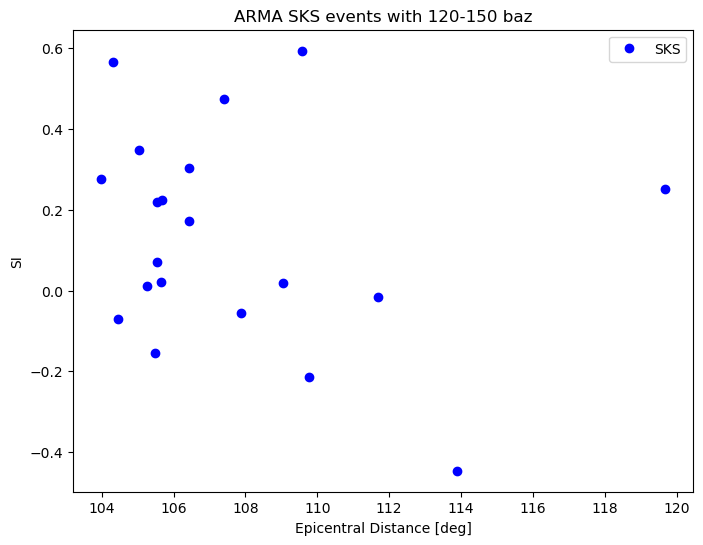

In [13]:
print(eventData['evstation'].unique())

truncatedData = eventData.copy()
truncatedData = truncatedData[truncatedData['evstation']=='BBOO']
truncatedData = truncatedData[truncatedData['evphase']=='SKS']
# # truncatedData = truncatedData[truncatedData['evdp']>=200]
truncatedData = truncatedData[(truncatedData['evbaz']>=140) & (truncatedData['evbaz']<=160)]
# # truncatedData = truncatedData[truncatedData['wiggleSI_calc']>=0]


truncatedData = truncatedData[['evstation','evtime','evlat','evlon','evdp','evmg','evphase','evepic','evbaz','calcbaz','wiggleSI_calc']]
truncatedData = truncatedData.sort_values(by='evepic')

truncatedData


s_truncatedData = truncatedData[truncatedData['evphase']=='S']
sks_truncatedData = truncatedData[truncatedData['evphase']=='SKS']

sks_shallow_truncatedData = sks_truncatedData[sks_truncatedData['evdp']<400]
sks_deep_truncatedData = sks_truncatedData[sks_truncatedData['evdp']>=400]

# plt.plot(truncatedData['evbaz'], truncatedData['wiggleSI_calc'], 'o',c='b')
# plt.plot(truncatedData['calcbaz'], truncatedData['wiggleSI_calc'], 'o',c='r')

# plt.plot(s_truncatedData['evbaz'], s_truncatedData['wiggleSI_calc'], 'o',c='r', label='S')
# plt.plot(sks_truncatedData['evbaz'], sks_truncatedData['wiggleSI_calc'], 'o',c='b', label='SKS')

plt.figure(figsize=(8,6))
# plt.plot(s_truncatedData['evepic'], s_truncatedData['wiggleSI_calc'], 'o',c='r', label='S')
plt.plot(sks_truncatedData['evepic'], sks_truncatedData['wiggleSI_calc'], 'o',c='blue', label='SKS')

# plt.plot(sks_shallow_truncatedData['evepic'], sks_shallow_truncatedData['wiggleSI_calc'], 'o',c='blue', label='SKS shallow')
# plt.plot(sks_deep_truncatedData['evepic'], sks_deep_truncatedData['wiggleSI_calc'], 'o',c='green', label='SKS deep')
plt.xlabel('Epicentral Distance [deg]')
# plt.xlim(100,200)
plt.ylabel('SI')
# plt.yticks(np.linspace(-2,2,9))
# plt.ylim(-2,2)
plt.legend()
plt.title('ARMA SKS events with 120-150 baz')
plt.show()

# print(f" Mean source latitude: {round(np.mean(truncatedData['evlat']),2)}")
# print(f" Mean source longitude: {round(np.mean(truncatedData['evlon']),2)}")


# truncatedData.to_csv('/work/gcl3/BR/nicolasv03/senior_thesis/codes/Plotting/ARMA_evbaz_120_to_150_events.txt')

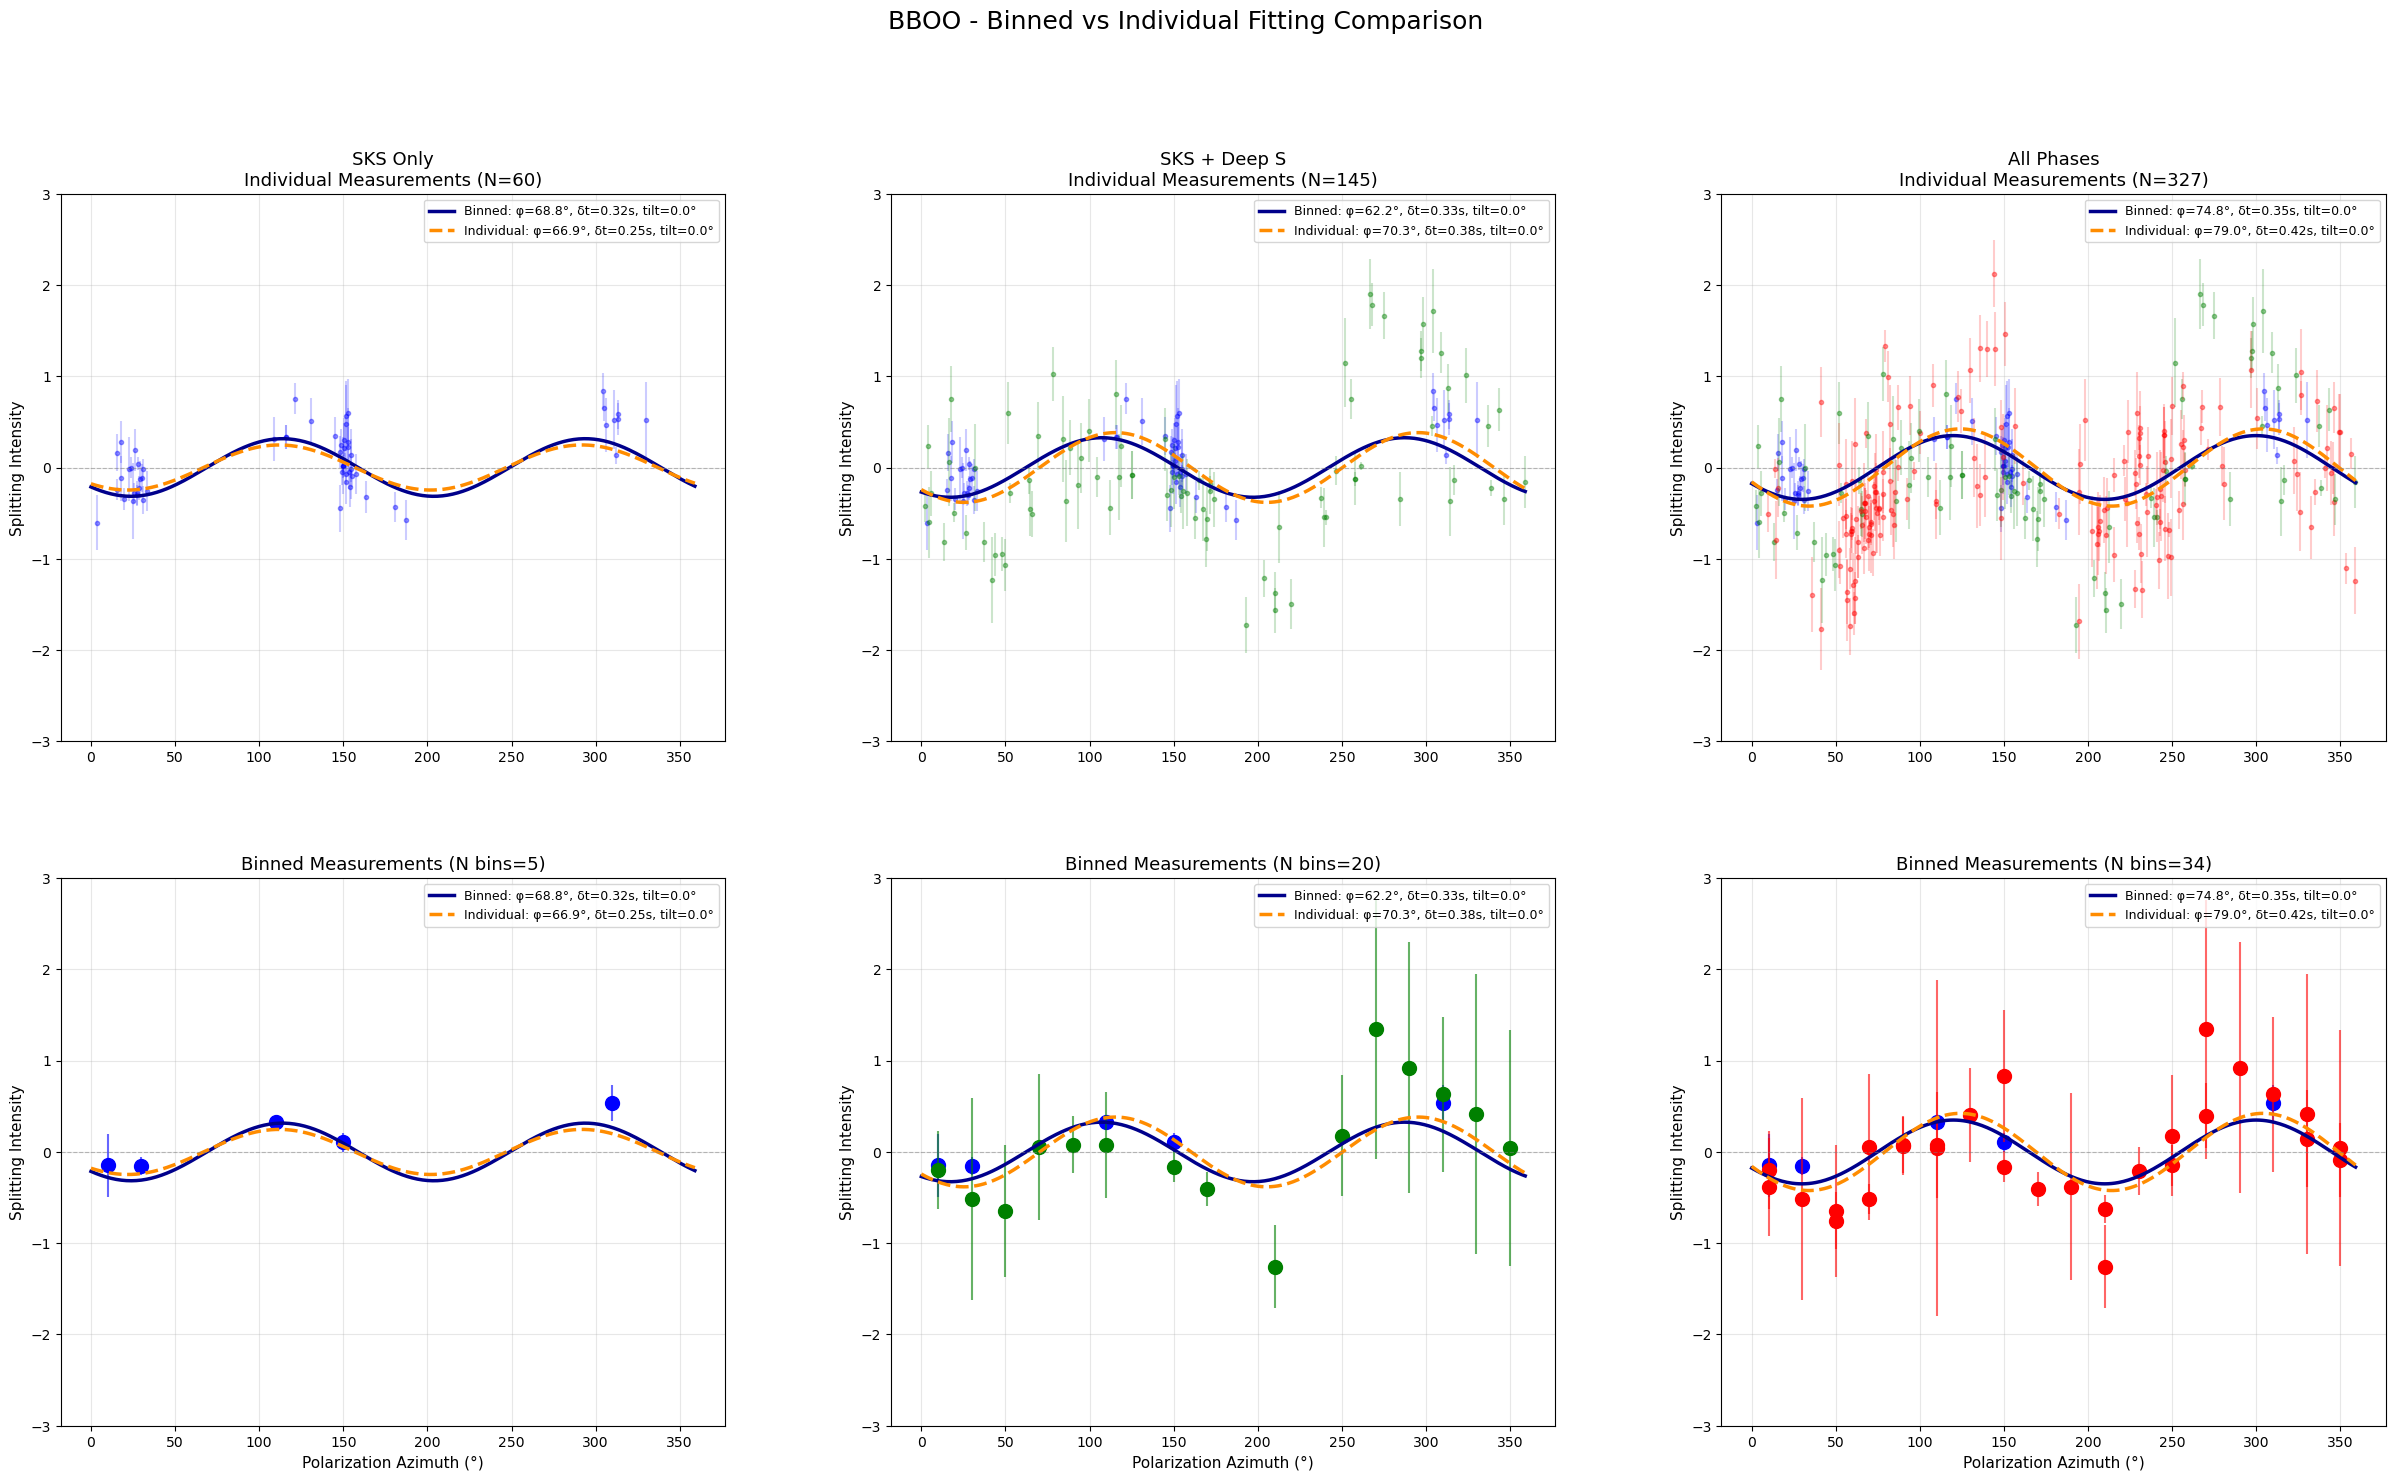

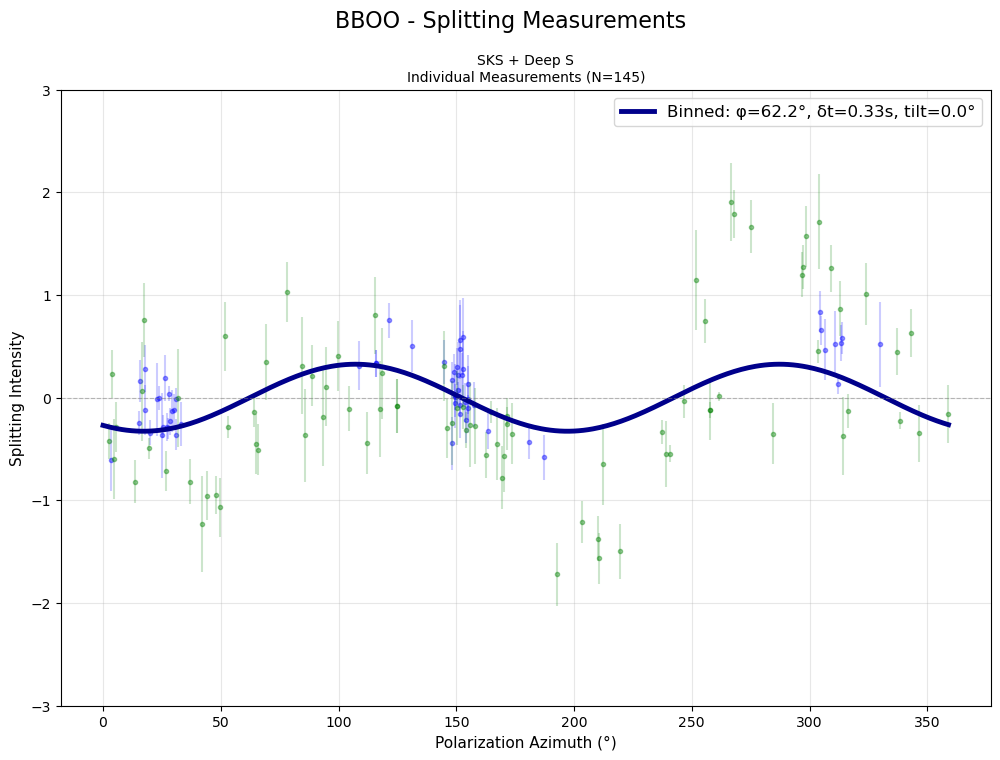

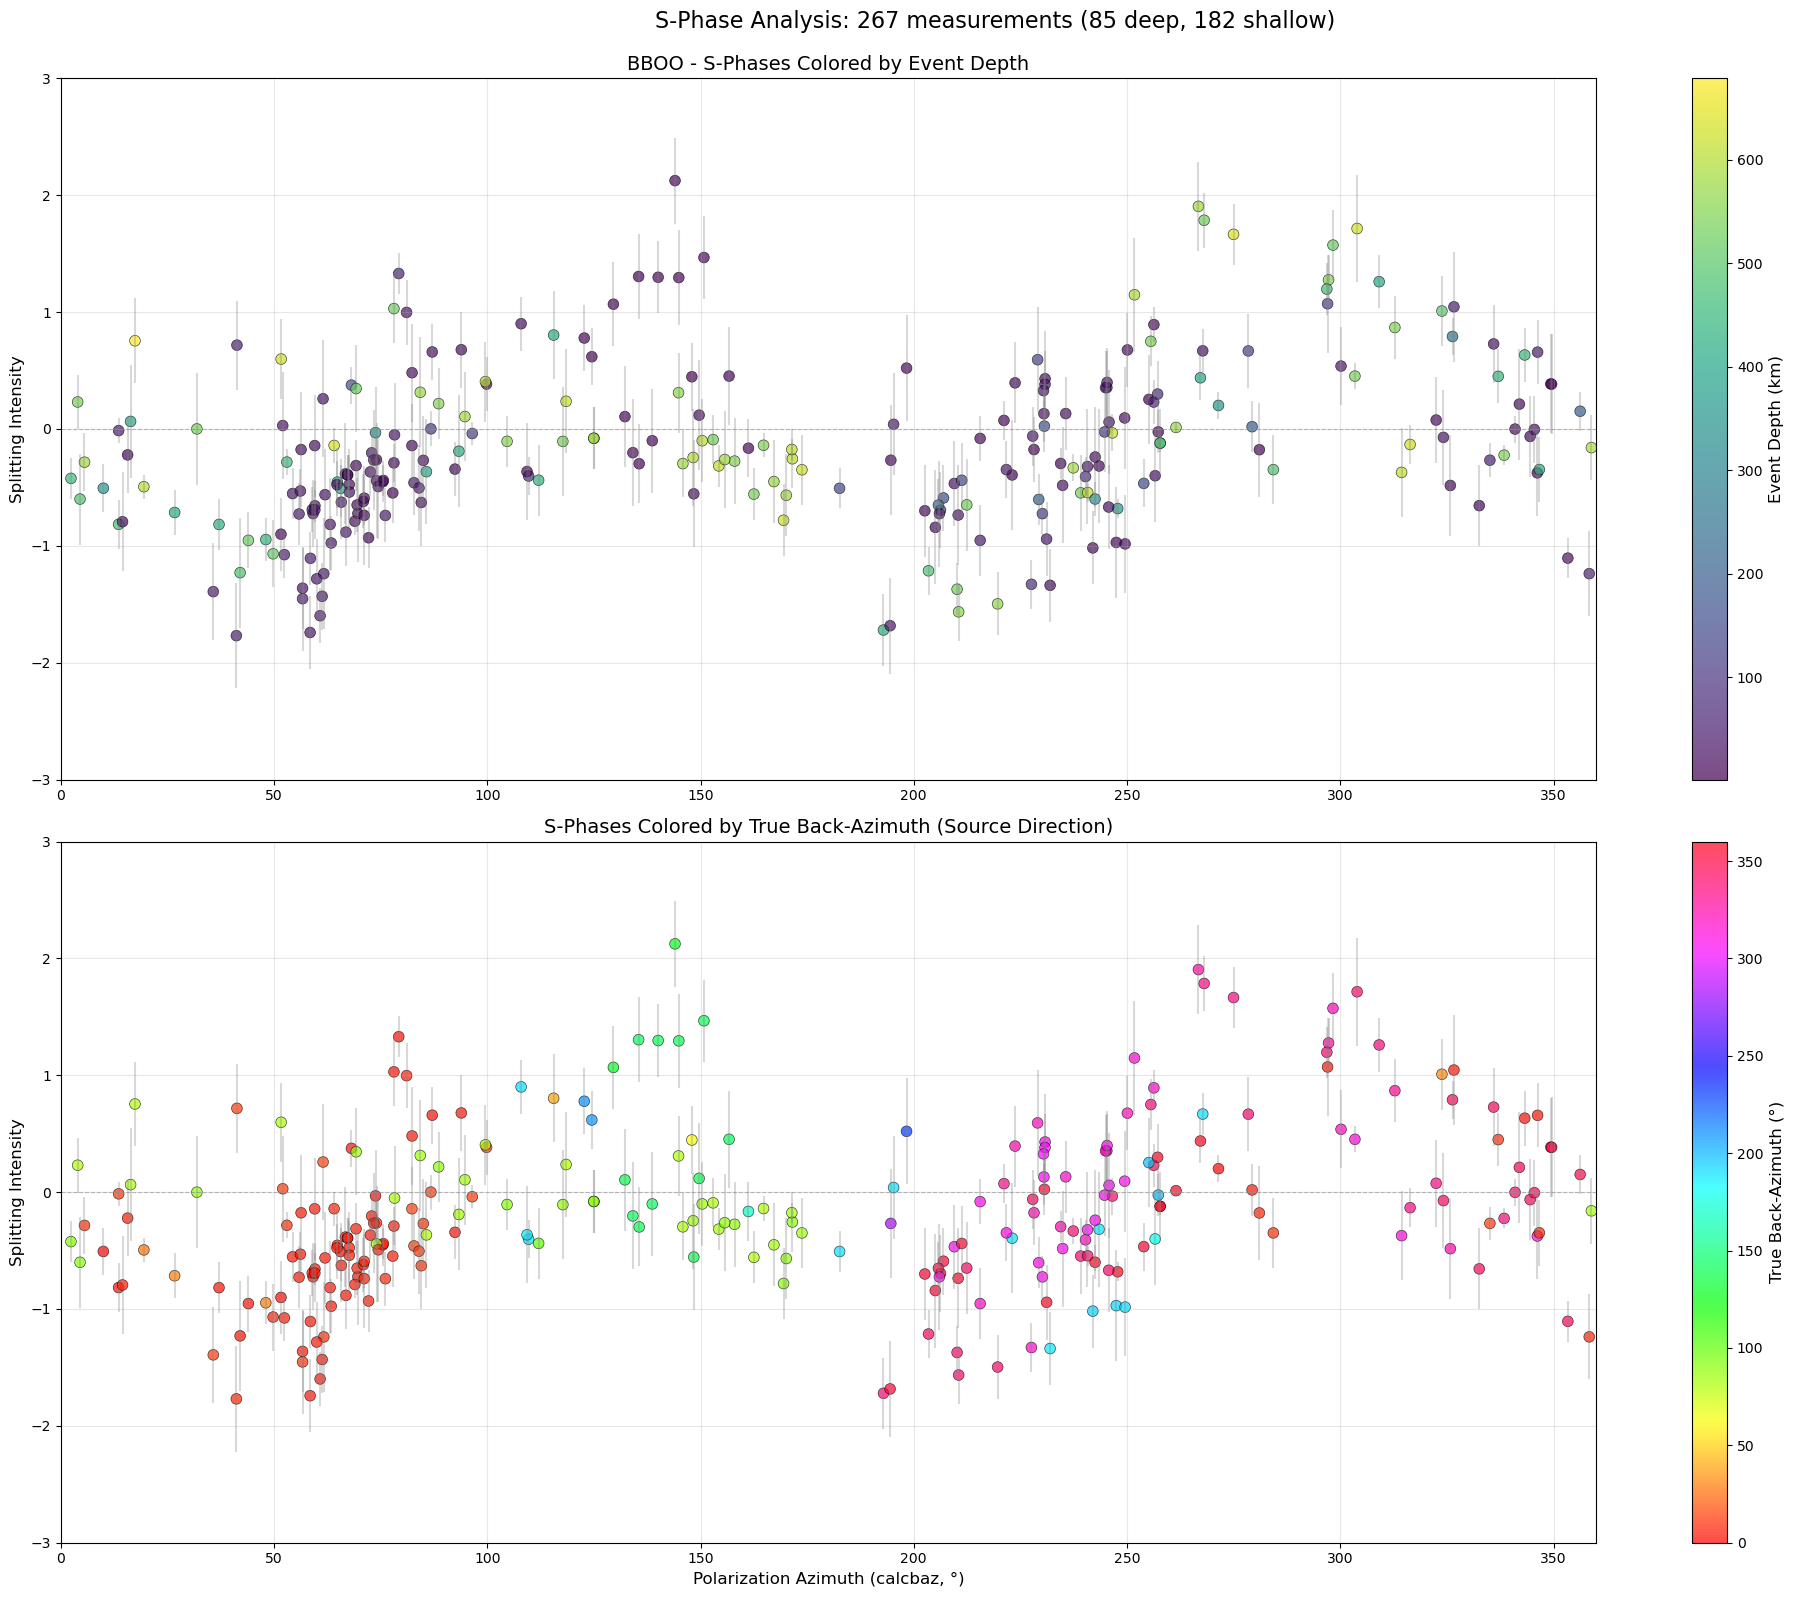

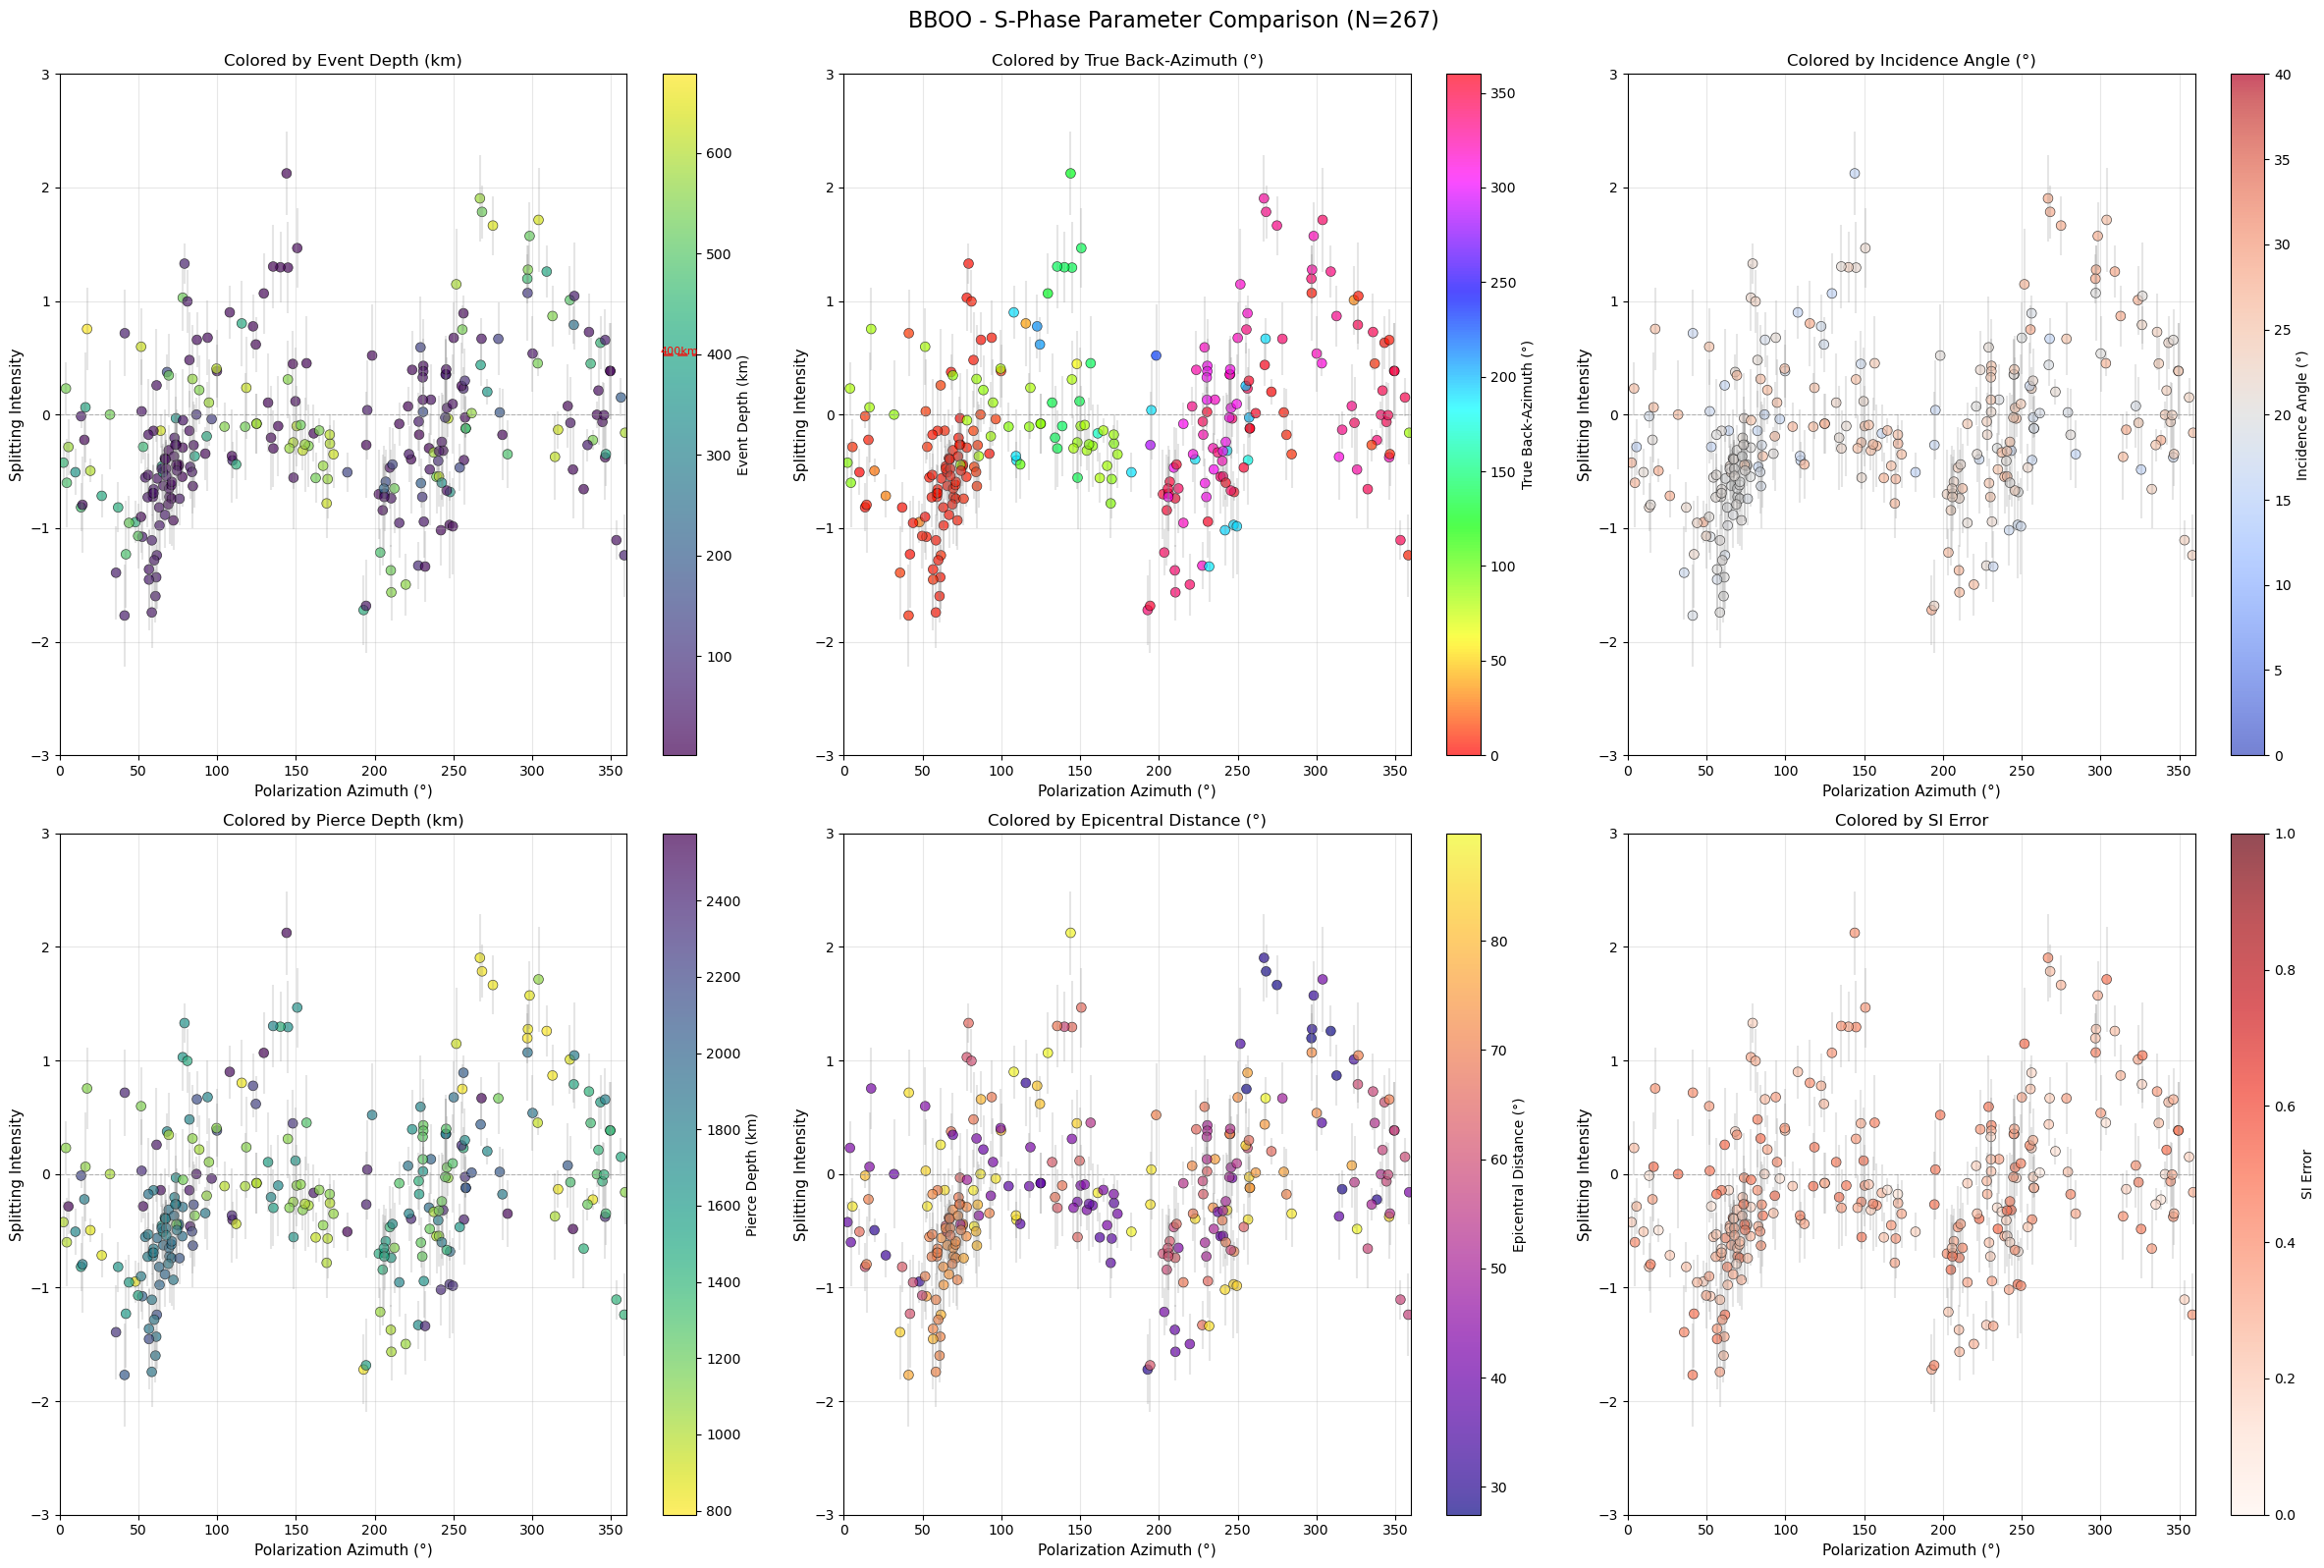

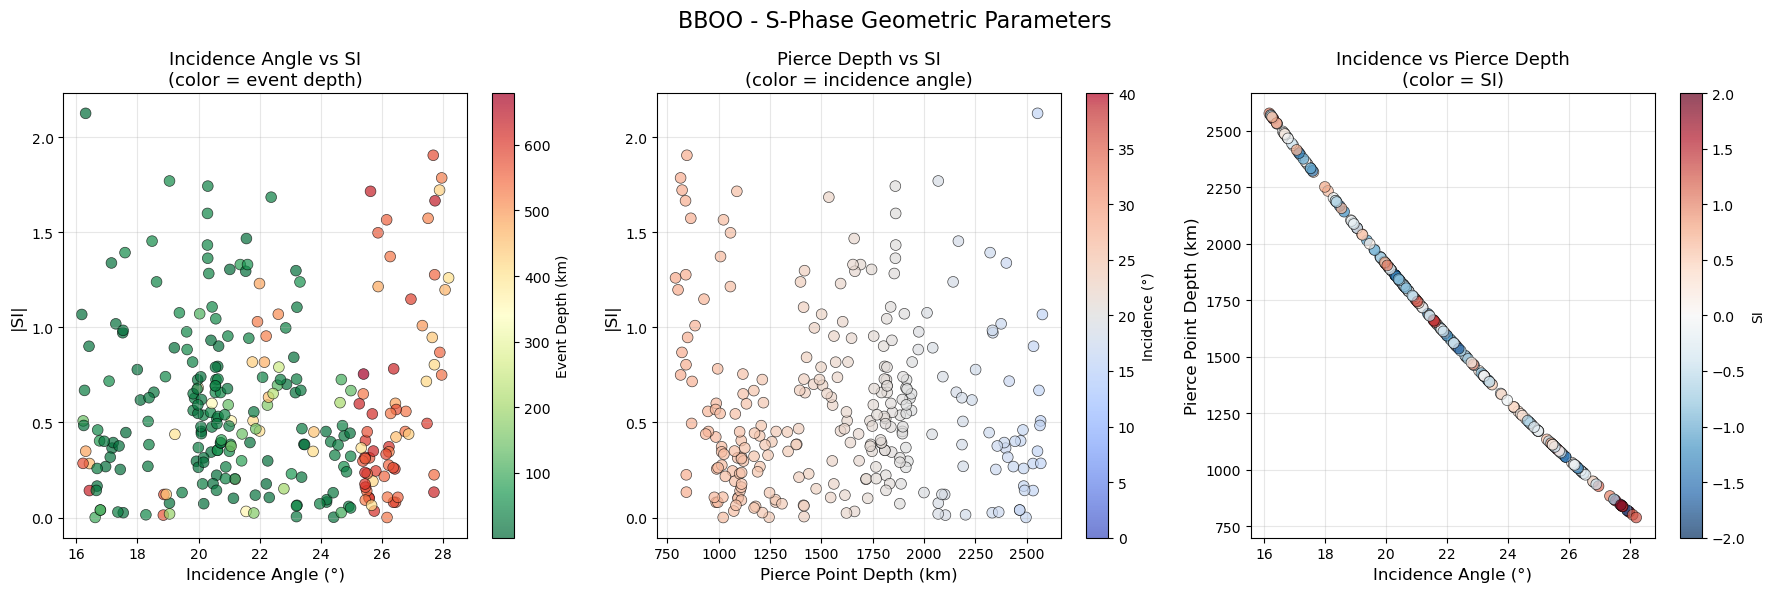


STATION SUMMARY: BBOO

Location:
  Latitude:  -32.810°
  Longitude: 136.059°
  Network:   AU
  Date range: 2005 - 2023

Measurements:
  SKS:              60
  S deep (≥400km):  85
  S shallow:        182
  Total:            327

Magnitude range: Mw 6.0 - 6.9

Splitting Parameters:



In [4]:


# Select station
# station_events = eventData 
station_code = 'BBOO'
station_events = eventData[eventData['evstation'] == station_code]
# station_events = station_events[station_events['evphase'] == 'S'] 
# station_events = station_events[~(station_events['calcbaz']>=300) & (station_events['calcbaz']<=350)]
# station_events = station_events[(station_events['calcbaz']<120)|(station_events['calcbaz']>150)]
# station_events = station_events[(~station_events['calcbaz']<120)|(~station_events['calcbaz']>150)]
# station_events = station_events[
#     (station_events['evphase'] != 'SKS') |  # Keep if not SKS
#     (station_events['calcbaz'] < 120) |      # OR if calcbaz < 120
#     (station_events['calcbaz'] > 150)      # OR if calcbaz > 150
# ]

# station_events = station_events[station_events['calcbaz']<300]

bin_width = 20
bin_minimum = 3

output_path = f'/work/gcl3/BR/nicolasv03/senior_thesis/measurements/spring_plots/{station_code}/'

# # ========== Plot 1: SI Curves for Different Phase Types ==========
results = analysis.analyze_station_comparison(station_events, station_code, bin_width=bin_width, bin_minimum=bin_minimum, s_depth=400, use_tilt=True)
fig1, stats = analysis.plot_station_comparison(results, station_code, s_depth=400)
# plt.savefig(output_path+f'AllSIPlots_bin_width_{bin_width}_min_{bin_minimum}_WeirdSKSBaz120to150.png', dpi=300, bbox_inches='tight')
plt.show()

fig1, stats = analysis.plot_station_sks_deep(results, station_code, s_depth=400,figsize=(12,8))
# plt.savefig(output_path+f'bin_width_{bin_width}_min_{bin_minimum}_WeirdSKSBaz120to150.png', dpi=300, bbox_inches='tight')

plt.show()


# ========== Plot 2: S Phase Depths and Back-Azimuths ==========
fig2, axes = plotting.plot_s_phases_dual_view(station_events, station_code, s_depth=400)
# plt.savefig(output_path+f'_sPhase_depth_and_back_azimuth.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 3: Comprehensive 6-panel comparison
fig3, axes = plotting.plot_s_phase_parameter_comparison(station_events, station_code)
plt.show()

# Plot 4: Incidence and pierce depth focused analysis
fig4, axes = plotting.plot_incidence_pierce_depth_grid(station_events, station_code)
plt.show()

# ========== Station Summary ==========
print("\n" + "="*70)
print(f"STATION SUMMARY: {station_code}")
print("="*70)

# Location
print(f"\nLocation:")
print(f"  Latitude:  {station_events['evstationlat'].iloc[0]:.3f}°")
print(f"  Longitude: {station_events['evstationlon'].iloc[0]:.3f}°")
print(f"  Network:   {station_events['evnetwork'].iloc[0] if 'evnetwork' in station_events.columns else 'N/A'}")

# Date range
if 'evtime' in station_events.columns:
    # Extract years from evtime (assumes format like 'YYYY-MM-DD...')
    dates = pd.to_datetime(station_events['evtime'], errors='coerce')
    print(f"  Date range: {dates.min().year} - {dates.max().year}")

# Measurements by phase type
n_sks = len(station_events[station_events['evphase'] == 'SKS'])
n_s_deep = len(station_events[(station_events['evphase'] == 'S') & (station_events['evdp'] >= 400)])
n_s_shallow = len(station_events[(station_events['evphase'] == 'S') & (station_events['evdp'] < 400)])

print(f"\nMeasurements:")
print(f"  SKS:              {n_sks}")
print(f"  S deep (≥400km):  {n_s_deep}")
print(f"  S shallow:        {n_s_shallow}")
print(f"  Total:            {len(station_events)}")

# Magnitude range
print(f"\nMagnitude range: Mw {station_events['evmg'].min():.1f} - {station_events['evmg'].max():.1f}")

# Splitting parameters (from different phase combinations in stats)
print(f"\nSplitting Parameters:")
for phase_key, label in [('sks', 'SKS only'), ('sks_deep', 'SKS + Deep S'), ('all', 'All phases')]:
    if phase_key in stats and stats[phase_key]:
        s = stats[phase_key]
        param_str = f"  {label:15s}: φ={s['phi_binned']:6.1f}°, δt={s['dt_binned']:.3f}s"
        if 'tilt_binned' in s and s['tilt_binned'] is not None:
            param_str += f", tilt={s['tilt_binned']:.1f}°"
        print(param_str)

print("="*70 + "\n")

# Loop Function: Generate Plots For ALL Stations in eventData

In [ ]:
# Parameters
bin_width = 30
bin_minimum = 3
s_depth = 400

# Get all unique stations
station_list = eventData['evstation'].unique()
print(f"Found {len(station_list)} unique stations")
print(f"Stations: {sorted(station_list)}")

# Filter to stations with minimum data
station_counts = eventData.groupby('evstation').size()
station_list = station_counts[station_counts >= 10].index.tolist()  # At least 10 measurements
print(f"\nProcessing {len(station_list)} stations with ≥10 measurements")

# Loop through stations
for station_code in station_list:
    print(f"\n{'='*70}")
    print(f"Processing {station_code}...")
    print('='*70)
    
    try:
        station_events = eventData[eventData['evstation'] == station_code]
        output_path = f'/work/gcl3/BR/nicolasv03/senior_thesis/measurements/spring_plots/april_10/{station_code}'
        
        # ========== Plot 1: SI Curves for Different Phase Types ==========
        print(f"  Generating SI curve plot...")
        results = analysis.analyze_station_comparison(
            eventData, 
            station_code, 
            bin_width=bin_width, 
            bin_minimum=bin_minimum, 
            s_depth=s_depth
        )
        
        fig1, stats = analysis.plot_station_comparison(results, station_code, s_depth=s_depth)
        plt.savefig(output_path + f'_si_curve_width_{bin_width}_min_{bin_minimum}.png', 
                   dpi=300, bbox_inches='tight')
        plt.close()  # Close instead of show to save memory
        print(f"    ✓ Saved SI curve plot")
        
        # ========== Plot 2: S Phase Depths and Back-Azimuths ==========
        print(f"  Generating S-phase depth/baz plot...")
        fig2, axes = plotting.plot_s_phases_dual_view(station_events, station_code, s_depth=s_depth)
        
        if fig2 is not None:  # Check if S-phase data exists
            plt.savefig(output_path + f'_sPhase_depth_and_back_azimuth.png', 
                       dpi=300, bbox_inches='tight')
            plt.close()
            print(f"    ✓ Saved S-phase plot")
        else:
            print(f"    - No S-phase data for this station")
        
        print(f"  ✓ Completed {station_code}")
        
    except Exception as e:
        print(f"  ✗ Failed on {station_code}: {e}")
        plt.close('all')  # Clean up any open figures
        continue

print(f"\n{'='*70}")
print(f"✓ Processing complete for {len(station_list)} stations")
print('='*70)

# new bootstrapping method

In [ ]:
# SKS + Deep S
eventData_sks_deep = eventData[(eventData['evphase'] == 'SKS') | 
                                ((eventData['evphase'] == 'S') & (eventData['evdp'] >= 400))]

eventData_sks_deep = eventData_sks_deep[(eventData_sks_deep['calcbaz']<120)|(eventData_sks_deep['calcbaz']>150)]

# eventData_sks_deep = eventData

station_code = 'ARMA'
# Run bootstrap (no tilt)
bootstrap_result = analysis.bootstrap_splitting_parameters(
    eventData_sks_deep,
    station_code=station_code,
    bin_width=20,
    bin_minimum=3,
    n_bootstrap=1000,
    use_tilt=False,
    subsample_fraction=1.0
)

# Plot results
fig, axes = plotting.plot_bootstrap_results(
    bootstrap_result,
    bootstrap_result['binned'],
    station_code=station_code
)
plt.show()

# # Or with tilt
# bootstrap_result_tilt = analysis.bootstrap_splitting_parameters(
#     eventData,
#     station_code='ARMA',
#     n_bootstrap=1000,
#     use_tilt=True
# )

# fig, axes = plotting.plot_bootstrap_results(bootstrap_result_tilt, bootstrap_result_tilt['binned'], 'ARMA')
# plt.show()